# Spike 2: floor ghost straight behind a real point

The first spike (`spike_ghost_planes.ipynb`) was blind to the floor ghost of a person who lies on the floor, because it dropped pairs closer than 0.3 m. This spike looks for it directly.

**Model.** The sensor looks down along y. A floor bounce puts a ghost G at about `y_G = 2h - y_P`, at the same x and z as the real point P. So we look for pairs in one frame where G is at least 0.1 m farther along y, within 0.3 m in x and in z, and weaker (lower SNR). Each pair gives a floor estimate `h = (y_P + y_G) / 2`. A real floor makes `h` pile up near one value (about 1.8 to 2.0 m).

**Control.** The same count for pairs from two frames far apart in time, scaled to the same number of candidate pairs. A second variant also needs equal Doppler (within 0.2 m/s).

**Pass rule.** In all 3 recordings: a peak above 5 sigma, in the same place, near the floor distance.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

OUT = Path("../../results/ghost_spike")
raw = json.load(open(OUT / "floor_summary.json"))
rows = []
for rec, s in raw.items():
    for variant in ("all", "doppler"):
        v = s[variant]
        rows.append({"recording": rec, "variant": variant, "median_y_lying_m": s["median_y_lying_m"], **{k: v[k] for k in
            ("pairs_within", "pairs_expected_from_control", "ratio_within_over_control", "peak_h_m", "peak_sigma", "sigma_in_window_1p6_2p0")}})
pd.DataFrame(rows).round(2)

,recording,variant,median_y_lying_m,pairs_within,pairs_expected_from_control,ratio_within_over_control,peak_h_m,peak_sigma,sigma_in_window_1p6_2p0
0,2311__20231115_135843,all,1.82,871,987.36,0.88,2.23,4.26,0.94
1,2311__20231115_135843,doppler,1.82,425,353.88,1.20,2.18,3.01,1.66
2,2311__20231120_144541,all,1.85,1464,1098.09,1.33,1.98,4.96,4.96
3,2311__20231120_144541,doppler,1.85,670,396.56,1.69,1.98,3.60,3.60
4,2311__20231120_153152,all,1.70,1384,1041.07,1.33,0.82,4.59,1.76
5,2311__20231120_153152,doppler,1.70,601,385.37,1.56,2.93,3.12,2.18


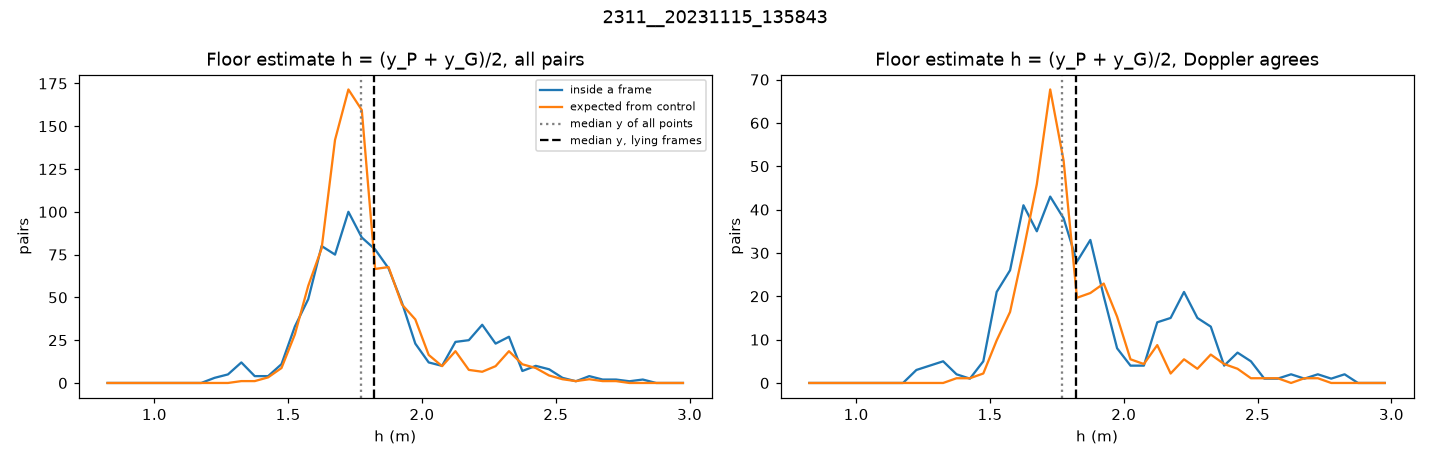

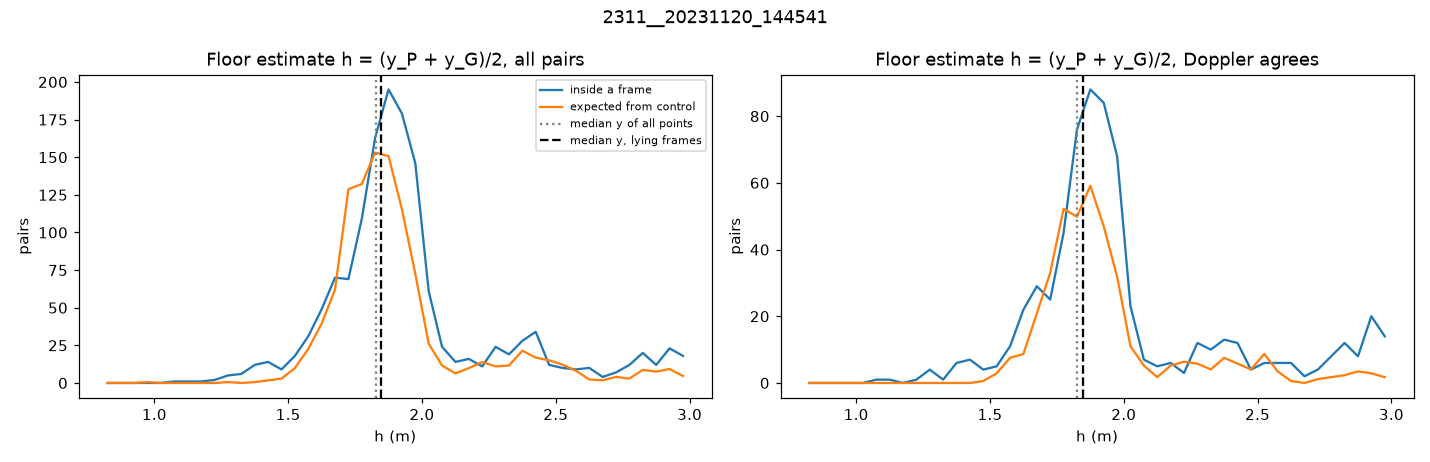

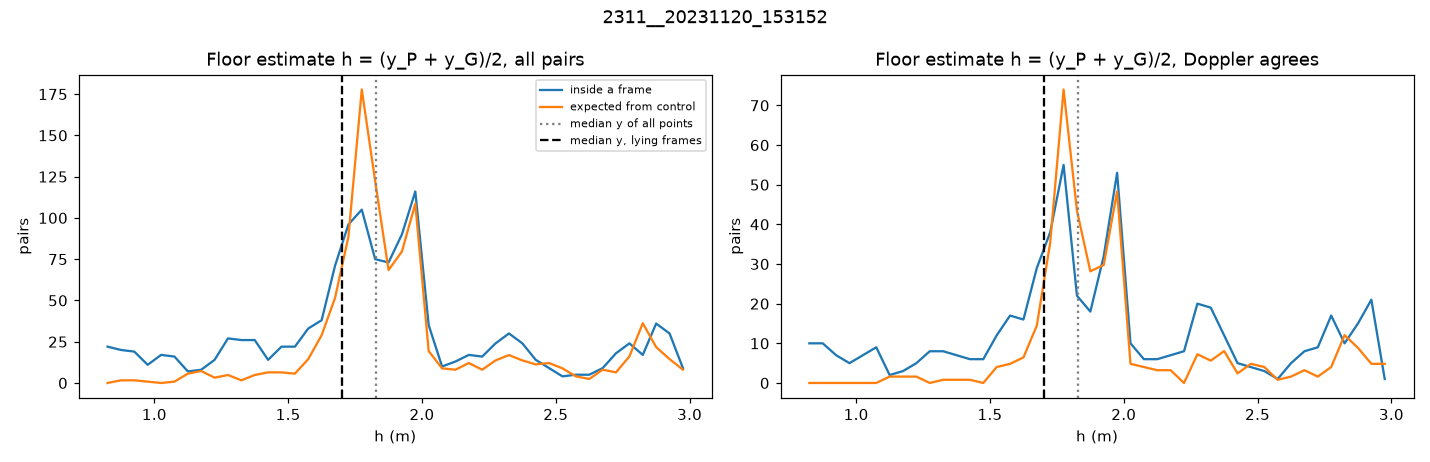

In [2]:
for name in raw:
    display(Image(str(OUT / f"floor_{name}.png")))

## Result: weak and inconsistent, not a pass

- **Peak position moves.** The best peak is at 2.2 m, 2.0 m and 0.8 m (all pairs), and at 2.2 m, 2.0 m and 2.9 m (Doppler variant). A real floor would be at the same distance in the three. Only `20231120_144541` has a peak near the floor, at 1.98 m and 5.0 sigma. The other two have 0.9 and 1.8 sigma in the 1.6 to 2.0 m window.
- **More pairs inside a frame than in the control.** For two recordings the ratio is 1.3, and for the Doppler variant it is 1.2 to 1.7 in all three. This is the only hint of structure.
- **That excess is probably not ghosts.** One person gives several points in a frame. Two body parts are at nearly the same x and z, at different y, with similar Doppler. They pass every rule and the control cannot remove them, because a control frame has a different person pose. So the excess may just be the body.

## Decision

The point clouds give no clear sign of floor multipath. The wall test (spike 1) gave nothing either. With the radar's 3 TX / 4 RX layout, only 2 to 7 points per frame, and clutter removal, I recommend that we **stop the ghost filter and the room-size estimate here** and not build the preprocessor.

If you still want one more attempt, the cleanest test uses the heatmap, not the points. The heatmap keeps all range bins, so a floor bounce would show as a copy of the person at a longer range. That test does not suffer from the 16-point limit per frame. It needs a new spike, and I would give it one more day at most.